In [3]:
 from sklearn.datasets import load_iris

 iris = load_iris()

 X = iris["data"]
 y = iris["target"]

 print(X.shape)
 print(y.shape)
 print(iris["target_names"])

(150, 4)
(150,)
['setosa' 'versicolor' 'virginica']


In [4]:
print(iris["feature_names"])

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [5]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()

df = pd.DataFrame(iris["data"], columns=iris["feature_names"])


In [6]:
X = df[
    ["petal length (cm)",
     "petal width (cm)"]
]

In [7]:
y = (iris["target"] == 2)

In [8]:
#boolean indexing
df_filtered = df[y == True]


In [9]:
import numpy


In [10]:
import pandas

In [11]:
import matplotlib.pyplot as plt


In [12]:
X = df[["petal length (cm)", "petal width (cm)"]].values


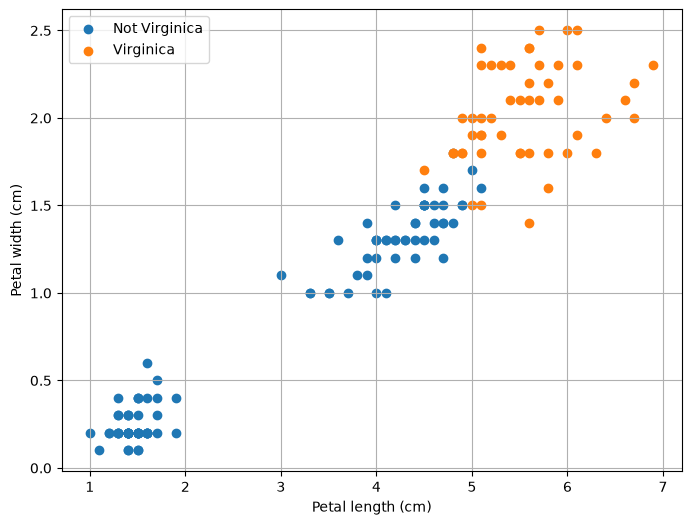

In [13]:
#classification problem
plt.figure(figsize=(8, 6))
plt.scatter(X[y == False, 0], X[y == False, 1], label="Not Virginica")
plt.scatter(X[y == True, 0], X[y == True, 1], label="Virginica")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend()
plt.grid()
plt.show()


In [14]:
#feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [15]:
#using the svc linear model
from sklearn.svm import SVC

svm_clf = SVC(
    kernel="linear",
    C=1
)

svm_clf.fit(
    X_scaled,
    y
)



,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [16]:
#Generating predictions
y_pred = svm_clf.predict(
    X_scaled,
)

print(y_pred[:10])

[False False False False False False False False False False]


In [17]:
#calculating the accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    y,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 0.9533333333333334


In [18]:
#Creating a mesh grid
import numpy as np
x0 = np.linspace(
X_scaled[:, 0].min()- 1,
X_scaled[:, 0].max() + 1,
200
)

x1 = np.linspace(
X_scaled[:, 1].min()- 1,
X_scaled[:, 1].max() + 1,
200
)
x0, x1 =np.meshgrid(x0, x1)
X_new = np.c_[
x0.ravel(),
x1.ravel()
]
y_pred_grid =svm_clf.predict(
X_new
)
y_pred_grid =y_pred_grid.reshape(
x0.shape
)

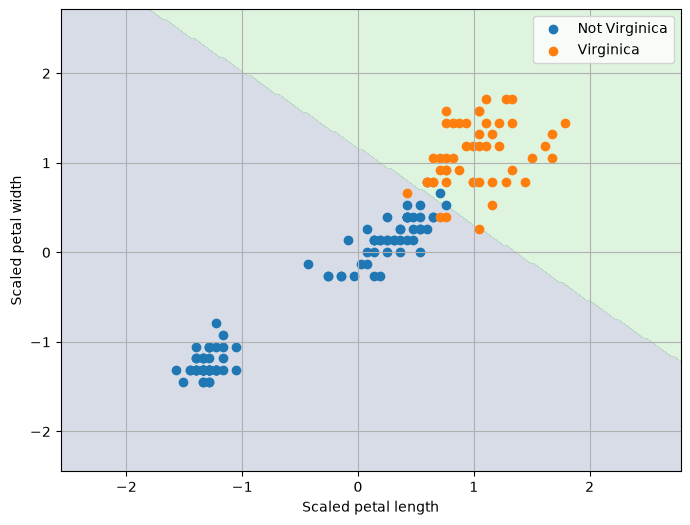

In [19]:
plt.figure(figsize=(8, 6))

plt.contourf(
    x0,
    x1,
    y_pred_grid,
    alpha=0.2
 )
plt.scatter(
    X_scaled[y == False, 0],
    X_scaled[y == False, 1],
    label="Not Virginica"
 )
plt.scatter(
    X_scaled[y == True, 0],
    X_scaled[y == True, 1],
    label="Virginica"
 )
plt.xlabel("Scaled petal length")
plt.ylabel("Scaled petal width")
plt.legend()
plt.grid()
plt.show()

In [20]:
print(svm_clf.support_)

[ 52  54  56  68  70  72  76  77  78  83  84  85  86 101 106 119 123 126
 127 129 133 134 138 142 146 149]


In [21]:
print(
    X_scaled[svm_clf.support_]
)

[[0.64908342 0.3957741 ]
 [0.47857113 0.3957741 ]
 [0.53540856 0.52740629]
 [0.42173371 0.3957741 ]
 [0.59224599 0.79067065]
 [0.64908342 0.3957741 ]
 [0.59224599 0.26414192]
 [0.70592084 0.65903847]
 [0.42173371 0.3957741 ]
 [0.76275827 0.52740629]
 [0.42173371 0.3957741 ]
 [0.42173371 0.52740629]
 [0.53540856 0.3957741 ]
 [0.76275827 0.92230284]
 [0.42173371 0.65903847]
 [0.70592084 0.3957741 ]
 [0.64908342 0.79067065]
 [0.59224599 0.79067065]
 [0.64908342 0.79067065]
 [1.16062026 0.52740629]
 [0.76275827 0.3957741 ]
 [1.0469454  0.26414192]
 [0.59224599 0.79067065]
 [0.76275827 0.92230284]
 [0.70592084 0.92230284]
 [0.76275827 0.79067065]]


In [22]:
C_values = [0.01, 0.1, 1, 10, 100]
for C_value in C_values:

    svm_clf = SVC(
        kernel="linear",
        C=C_value
    )

    svm_clf.fit(
        X_scaled,
        y
    )

    predictions = svm_clf.predict(
        X_scaled
    )

    accuracy = accuracy_score(
        y,
        predictions
    )

    print(
        "C =", C_value,
        "Accuracy =", accuracy
    )


C = 0.01 Accuracy = 0.96
C = 0.1 Accuracy = 0.96
C = 1 Accuracy = 0.9533333333333334
C = 10 Accuracy = 0.9666666666666667
C = 100 Accuracy = 0.96


In [23]:
#using cross validation to compare models
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC

C_values = [0.01, 0.1, 1, 10, 100]

for C_value in C_values:
    svm_clf = SVC(
        kernel="linear",
        C=C_value
    )

    scores = cross_val_score(
        svm_clf,
        X_scaled,
        y,
        cv=5,               # 5-fold cross-validation
        scoring="accuracy"
    )

    print(
        "C =", C_value,
        "Mean Accuracy =", scores.mean(),
        "Std =", scores.std()
    )


C = 0.01 Mean Accuracy = 0.6933333333333332 Std = 0.11035296904831235
C = 0.1 Mean Accuracy = 0.9533333333333334 Std = 0.04521553322083511
C = 1 Mean Accuracy = 0.9533333333333334 Std = 0.04521553322083511
C = 10 Mean Accuracy = 0.9533333333333334 Std = 0.04521553322083511
C = 100 Mean Accuracy = 0.9533333333333334 Std = 0.04521553322083511


In [24]:
#Not all classification problems can beseparated using as traight line.One approach is to trans
#form the original features into additional non linearfeatures.

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

poly_svm_clf = Pipeline([
    (
        "poly_features",
        PolynomialFeatures(degree=3)
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svm",
        SVC(
            kernel="linear",
            C=10
        )
    )
])

poly_svm_clf.fit(
    X,
    y
)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly_features', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",3
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [25]:
#creating an svm using polynomial kernel
poly_kernel_svm = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svm",
        SVC(
            kernel="poly",
            degree=3,
            coef0=1,
            C=5
        )
    )
])

poly_kernel_svm.fit(
    X,
    y
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [26]:
predictions = poly_kernel_svm.predict(
    X
)

accuracy_score(
    y,
    predictions
)

0.96

In [27]:
#create an svm using the rbf kernel

rbf_svm = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svm",
        SVC(
            kernel="rbf",
            C=1,
            gamma=1
        )
    )
])

rbf_svm.fit(
    X,
    y
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [28]:
#Generate predictions and calculate accuracy

predictions = rbf_svm.predict(
    X
)

print(
    accuracy_score(
        y,
        predictions
    )
)


0.96


In [29]:
gamma_values = [
    0.01,
    0.1,
    1,
    10,
    100
]

for gamma_value in gamma_values:

    model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                C=1,
                gamma=gamma_value
            )
        )
    ])

    model.fit(X, y)

    predictions = model.predict(X)

    print(
        "gamma =", gamma_value,
        "accuracy =",
        accuracy_score(y, predictions)
    )


gamma = 0.01 accuracy = 0.9533333333333334
gamma = 0.1 accuracy = 0.9533333333333334
gamma = 1 accuracy = 0.96
gamma = 10 accuracy = 0.9666666666666667
gamma = 100 accuracy = 0.9933333333333333


In [30]:
#comparing svm classicfication models
from sklearn.model_selection import cross_val_score

models = {
    "Linear SVM": svm_clf,
    "Polynomial Kernel": poly_kernel_svm,
    "RBF Kernel": rbf_svm
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    print(
        name,
        "Mean accuracy:",
        scores.mean(),
        "Std:",
        scores.std()
    )

Linear SVM Mean accuracy: 0.9533333333333334 Std: 0.04521553322083511
Polynomial Kernel Mean accuracy: 0.9533333333333334 Std: 0.04521553322083511
RBF Kernel Mean accuracy: 0.9533333333333334 Std: 0.04521553322083511


In [ ]:
#Svm for regression
#load the dataset
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(
    as_frame=True
)

X = housing.data
y = housing.target

In [32]:
#split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )
)

In [36]:
from sklearn.svm import LinearSVR

linear_svr = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svr",
        LinearSVR(
            epsilon=0.5,
            random_state=42
        )
    )
])

linear_svr.fit(
    X_train,
    y_train
)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [37]:
y_pred = linear_svr.predict(
    X_test
)

In [38]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

print("RMSE:", rmse)

RMSE: 0.7510784429810207


In [39]:
#Nonlinear SVM Regression

from sklearn.svm import SVR

rbf_svr = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svr",
        SVR(
            kernel="rbf",
            C=100,
            gamma="scale",
            epsilon=0.1
        )
    )
])

rbf_svr.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [40]:
y_pred = rbf_svr.predict(
    X_test
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

print("RBF SVR RMSE:", rmse)

RBF SVR RMSE: 0.5657769203689226
